# DSCI 552 - Homework 7

**Name:** Nithya Prasasthani Eeri  
**GitHub Username:** Nithya0605-eeri
**USC ID:** 9182042369

In [24]:
# Required libraries

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC, LinearSVC
from sklearn.multiclass import OneVsRestClassifier
from sklearn.metrics import accuracy_score, hamming_loss, silhouette_score
from sklearn.cluster import KMeans
from sklearn.pipeline import Pipeline
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline
from sklearn.cluster import MiniBatchKMeans
from sklearn.metrics import calinski_harabasz_score
from scipy.cluster.hierarchy import linkage, dendrogram
from scipy.spatial.distance import squareform

import warnings
warnings.filterwarnings("ignore")

RANDOM_STATE = 42

print("All libraries imported successfully!")

All libraries imported successfully!


## 1. Multi-Class and Multi-Label Classification Using Support Vector Machines

### 1(a) Data Loading and Train-Test Split

The Anuran Calls (MFCCs) dataset contains acoustic features and three classification labels: Family, Genus, and Species. We randomly select 70% of the observations for training and reserve 30% for testing.

In [2]:
# Question 1(a): Load and inspect the dataset

df = pd.read_csv("../data/Frogs_MFCCs.csv")

print("Dataset shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

print("\nMissing values:", df.isnull().sum().sum())

display(df.head())

Dataset shape: (7195, 26)

Column names:
['MFCCs_ 1', 'MFCCs_ 2', 'MFCCs_ 3', 'MFCCs_ 4', 'MFCCs_ 5', 'MFCCs_ 6', 'MFCCs_ 7', 'MFCCs_ 8', 'MFCCs_ 9', 'MFCCs_10', 'MFCCs_11', 'MFCCs_12', 'MFCCs_13', 'MFCCs_14', 'MFCCs_15', 'MFCCs_16', 'MFCCs_17', 'MFCCs_18', 'MFCCs_19', 'MFCCs_20', 'MFCCs_21', 'MFCCs_22', 'Family', 'Genus', 'Species', 'RecordID']

Missing values: 0


,MFCCs_ 1,MFCCs_ 2,MFCCs_ 3,MFCCs_ 4,MFCCs_ 5,MFCCs_ 6,MFCCs_ 7,MFCCs_ 8,MFCCs_ 9,MFCCs_10,...,MFCCs_17,MFCCs_18,MFCCs_19,MFCCs_20,MFCCs_21,MFCCs_22,Family,Genus,Species,RecordID
0,1.0,0.152936,-0.105586,0.200722,0.317201,0.260764,0.100945,-0.150063,-0.171128,0.124676,...,-0.108351,-0.077623,-0.009568,0.057684,0.118680,0.014038,Leptodactylidae,Adenomera,AdenomeraAndre,1
1,1.0,0.171534,-0.098975,0.268425,0.338672,0.268353,0.060835,-0.222475,-0.207693,0.170883,...,-0.090974,-0.056510,-0.035303,0.020140,0.082263,0.029056,Leptodactylidae,Adenomera,AdenomeraAndre,1
2,1.0,0.152317,-0.082973,0.287128,0.276014,0.189867,0.008714,-0.242234,-0.219153,0.232538,...,-0.050691,-0.023590,-0.066722,-0.025083,0.099108,0.077162,Leptodactylidae,Adenomera,AdenomeraAndre,1
3,1.0,0.224392,0.118985,0.329432,0.372088,0.361005,0.015501,-0.194347,-0.098181,0.270375,...,-0.136009,-0.177037,-0.130498,-0.054766,-0.018691,0.023954,Leptodactylidae,Adenomera,AdenomeraAndre,1
4,1.0,0.087817,-0.068345,0.306967,0.330923,0.249144,0.006884,-0.265423,-0.172700,0.266434,...,-0.048885,-0.053074,-0.088550,-0.031346,0.108610,0.079244,Leptodactylidae,Adenomera,AdenomeraAndre,1


In [3]:
# Question 1(a): Train-test split

# Separate features and target labels
X = df.drop(columns=["Family", "Genus", "Species", "RecordID"])
y = df[["Family", "Genus", "Species"]]

# Random 70/30 train-test split
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=RANDOM_STATE,
    shuffle=True
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)
print("Training labels:", y_train.shape)
print("Testing labels:", y_test.shape)

print("\nTraining percentage:", round(len(X_train) / len(X) * 100, 2))
print("Testing percentage:", round(len(X_test) / len(X) * 100, 2))

Training features: (5036, 22)
Testing features: (2159, 22)
Training labels: (5036, 3)
Testing labels: (2159, 3)

Training percentage: 69.99
Testing percentage: 30.01


### 1(b)(i) Multi-Label Classification Evaluation Metrics

**Exact Match (Subset Accuracy):** The proportion of samples for which all three predicted labels (Family, Genus, and Species) match the true labels. Higher values indicate better performance.

**Hamming Loss:** The fraction of incorrectly predicted labels across all samples and label positions. Lower values indicate better performance.

**Hamming Score:** The fraction of correctly predicted labels across all samples and label positions, calculated as 1 - Hamming Loss. Higher values indicate better performance.

Exact match is stricter because a prediction is correct only when all three labels match, whereas Hamming metrics evaluate each label separately.

In [7]:
# Question 1(b)(i): Evaluation metrics

def evaluate_multilabel(y_true, y_pred):
    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)

    correct = (y_true == y_pred)

    exact_match = np.mean(np.all(correct, axis=1))
    loss = np.mean(~correct)
    score = np.mean(correct)

    return {
        "Exact Match": round(exact_match, 4),
        "Hamming Score": round(score, 4),
        "Hamming Loss": round(loss, 4)
    }

print("Evaluation function updated successfully!")

Evaluation function updated successfully!


### 1(b)(ii) Gaussian Kernel SVM with 10-Fold Cross-Validation

Three separate One-vs-Rest SVM classifiers are trained to predict Family, Genus, and Species using an RBF kernel.

The penalty parameter C and kernel coefficient gamma are selected using 10-fold cross-validation. StandardScaler is included in the pipeline to standardize features without leaking information from the validation folds.

The best models will be evaluated on the held-out test set using exact match, Hamming score, and Hamming loss.

In [5]:
# Question 1(b)(ii): Gaussian Kernel SVM

rbf_models = {}
rbf_predictions = pd.DataFrame(index=y_test.index)
rbf_results = []

param_grid = {
    "classifier__estimator__C": [0.1, 1, 10, 100],
    "classifier__estimator__gamma": [0.001, 0.01, 0.1, 1]
}

cv = StratifiedKFold(
    n_splits=10,
    shuffle=True,
    random_state=RANDOM_STATE
)

for label in ["Family", "Genus", "Species"]:
    print(f"\nTraining Gaussian SVM for {label}...")

    pipeline = Pipeline([
        ("scaler", StandardScaler()),
        ("classifier", OneVsRestClassifier(
            SVC(kernel="rbf")
        ))
    ])

    grid_search = GridSearchCV(
        estimator=pipeline,
        param_grid=param_grid,
        cv=cv,
        scoring="accuracy",
        n_jobs=-1
    )

    grid_search.fit(X_train, y_train[label])

    rbf_models[label] = grid_search.best_estimator_
    rbf_predictions[label] = grid_search.predict(X_test)

    rbf_results.append({
        "Label": label,
        "Best C": grid_search.best_params_["classifier__estimator__C"],
        "Best Gamma": grid_search.best_params_["classifier__estimator__gamma"],
        "CV Accuracy": grid_search.best_score_,
        "Test Accuracy": accuracy_score(
            y_test[label], rbf_predictions[label]
        )
    })

rbf_results_df = pd.DataFrame(rbf_results)
display(rbf_results_df)


Training Gaussian SVM for Family...

Training Gaussian SVM for Genus...

Training Gaussian SVM for Species...


,Label,Best C,Best Gamma,CV Accuracy,Test Accuracy
0,Family,10,0.1,0.990468,0.993516
1,Genus,10,0.1,0.989078,0.988421
2,Species,10,0.1,0.988880,0.987957


In [8]:
# Question 1(b)(ii): Evaluate Gaussian SVM

rbf_metrics = evaluate_multilabel(
    y_test,
    rbf_predictions[y_test.columns]
)

print("Gaussian Kernel SVM - Test Results")
for metric, value in rbf_metrics.items():
    print(f"{metric}: {value:.4f}")

Gaussian Kernel SVM - Test Results
Exact Match: 0.9866
Hamming Score: 0.9900
Hamming Loss: 0.0100


**Conclusion — Gaussian Kernel SVM**

The Gaussian SVM achieved an exact match accuracy of 98.66%, a Hamming score of 99.00%, and a Hamming loss of 1.00% on the test set.

The best hyperparameters were C = 10 and gamma = 0.1 for all three labels, selected using 10-fold cross-validation.

These results indicate strong multi-label classification performance. The low Hamming loss shows that very few individual labels were incorrectly predicted.

### 1(b)(iii) L1-Penalized Linear SVM

L1-penalized linear SVMs are trained separately for Family, Genus, and Species using standardized features and One-vs-Rest classification. The penalty parameter C is selected using 10-fold cross-validation.

In [10]:
# Question 1(b)(iii): L1-Penalized Linear SVM

l1_models = {}
l1_predictions = pd.DataFrame(index=y_test.index)
l1_results = []

l1_param_grid = {
    "classifier__estimator__C": [0.001, 0.01, 0.1, 1, 10, 100]
}

for label in ["Family", "Genus", "Species"]:
    pipeline = Pipeline([
        ("scaler", StandardScaler()),
        ("classifier", OneVsRestClassifier(
            LinearSVC(
                penalty="l1",
                dual=False,
                max_iter=20000,
                random_state=RANDOM_STATE
            )
        ))
    ])

    grid = GridSearchCV(
        pipeline,
        l1_param_grid,
        cv=cv,
        scoring="accuracy",
        n_jobs=-1
    )

    grid.fit(X_train, y_train[label])

    l1_models[label] = grid.best_estimator_
    l1_predictions[label] = grid.predict(X_test)

    l1_results.append({
        "Label": label,
        "Best C": grid.best_params_["classifier__estimator__C"],
        "CV Accuracy": round(grid.best_score_, 4),
        "Test Accuracy": round(
            accuracy_score(y_test[label], l1_predictions[label]), 4
        )
    })

display(pd.DataFrame(l1_results))

/Users/enithyaprasasthani/anaconda3/lib/python3.11/site-packages/sklearn/svm/_base.py:1250: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
/Users/enithyaprasasthani/anaconda3/lib/python3.11/site-packages/sklearn/svm/_base.py:1250: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(


,Label,Best C,CV Accuracy,Test Accuracy
0,Family,10,0.9412,0.9282
1,Genus,100,0.9516,0.9416
2,Species,10,0.9607,0.9592


In [11]:
# Question 1(b)(iii): L1 SVM evaluation

l1_metrics = evaluate_multilabel(
    y_test,
    l1_predictions[y_test.columns]
)

print("L1-Penalized SVM - Test Results")
for metric, value in l1_metrics.items():
    print(f"{metric}: {value:.4f}")

L1-Penalized SVM - Test Results
Exact Match: 0.9125
Hamming Score: 0.9430
Hamming Loss: 0.0570


### 1(b)(iv) L1-Penalized SVM with SMOTE

SMOTE is applied within each training fold to address class imbalance. Standardized features and L1-penalized One-vs-Rest SVMs are used, with C selected through 10-fold cross-validation.

In [12]:
# Question 1(b)(iv): L1 SVM with SMOTE

smote_predictions = pd.DataFrame(index=y_test.index)
smote_results = []
smote_models = {}

for label in ["Family", "Genus", "Species"]:
    pipeline = ImbPipeline([
        ("scaler", StandardScaler()),
        ("smote", SMOTE(random_state=RANDOM_STATE, k_neighbors=3)),
        ("classifier", OneVsRestClassifier(
            LinearSVC(
                penalty="l1",
                dual=False,
                max_iter=20000,
                random_state=RANDOM_STATE
            )
        ))
    ])

    grid = GridSearchCV(
        pipeline,
        {"classifier__estimator__C": [0.001, 0.01, 0.1, 1, 10, 100]},
        cv=cv,
        scoring="accuracy",
        n_jobs=-1
    )

    grid.fit(X_train, y_train[label])

    smote_models[label] = grid.best_estimator_
    smote_predictions[label] = grid.predict(X_test)

    smote_results.append({
        "Label": label,
        "Best C": grid.best_params_["classifier__estimator__C"],
        "CV Accuracy": round(grid.best_score_, 4),
        "Test Accuracy": round(
            accuracy_score(y_test[label], smote_predictions[label]), 4
        )
    })

display(pd.DataFrame(smote_results))

,Label,Best C,CV Accuracy,Test Accuracy
0,Family,10,0.9212,0.9069
1,Genus,100,0.9124,0.9027
2,Species,1,0.9579,0.9597


In [13]:
# Question 1(b)(iv): Final SVM comparison

smote_metrics = evaluate_multilabel(
    y_test,
    smote_predictions[y_test.columns]
)

comparison = pd.DataFrame(
    [rbf_metrics, l1_metrics, smote_metrics],
    index=["Gaussian SVM", "L1 SVM", "L1 SVM + SMOTE"]
)

display(comparison)

,Exact Match,Hamming Score,Hamming Loss
Gaussian SVM,0.9866,0.9900,0.0100
L1 SVM,0.9125,0.9430,0.0570
L1 SVM + SMOTE,0.8527,0.9231,0.0769


**Conclusion — SVM Comparison**

The Gaussian SVM achieved the best performance, with 98.66% exact match and 1.00% Hamming loss. The L1 SVM achieved 91.25% exact match, while SMOTE reduced it to 85.27%. Thus, the nonlinear Gaussian SVM performed best, and SMOTE did not improve overall classification accuracy on this dataset.

## 2. K-Means Clustering on a Multi-Class and Multi-Label Dataset

### 2(a) Selecting the Number of Clusters

K-Means is applied to all 7,195 observations using the 22 MFCC features. The number of clusters is selected from K = 1 to 50 using the Calinski-Harabasz (CH) index, which evaluates cluster separation and compactness.

In [15]:
# Question 2(a): Prepare full dataset for clustering

from sklearn.metrics import calinski_harabasz_score

X_cluster = df.drop(
    columns=["Family", "Genus", "Species", "RecordID"]
)

y_cluster = df[["Family", "Genus", "Species"]]

print("Clustering features:", X_cluster.shape)
print("True labels:", y_cluster.shape)

Clustering features: (7195, 22)
True labels: (7195, 3)


In [16]:
# Question 2(a): Select K using Calinski-Harabasz index

k_values = range(2, 51)
ch_scores = []

for k in k_values:
    model = KMeans(
        n_clusters=k,
        random_state=RANDOM_STATE,
        n_init=10
    )
    labels = model.fit_predict(X_cluster)
    ch_scores.append(calinski_harabasz_score(X_cluster, labels))

best_k = list(k_values)[np.argmax(ch_scores)]
print("Optimal number of clusters:", best_k)
print("Best CH score:", round(max(ch_scores), 2))

Optimal number of clusters: 2
Best CH score: 3680.74


### 2(b) Majority Labels per Cluster

For each cluster, the most frequent Family, Genus, and Species labels are identified using the true labels.

In [17]:
# Question 2(b): Majority labels for each cluster

kmeans = KMeans(
    n_clusters=best_k,
    random_state=RANDOM_STATE,
    n_init=10
)

cluster_labels = kmeans.fit_predict(X_cluster)

cluster_df = y_cluster.copy()
cluster_df["Cluster"] = cluster_labels

majority_labels = cluster_df.groupby("Cluster")[
    ["Family", "Genus", "Species"]
].agg(lambda x: x.value_counts().idxmax())

display(majority_labels)

,Family,Genus,Species
Cluster,,,
0,Leptodactylidae,Adenomera,AdenomeraHylaedactylus
1,Hylidae,Hypsiboas,HypsiboasCordobae


### 2(c) Hamming Metrics and Monte Carlo Simulation

Each observation is assigned the majority-label triplet of its cluster. Hamming distance counts incorrect labels per observation, Hamming loss is the proportion of incorrect labels, and Hamming score is the proportion of correct labels. The experiment is repeated 50 times to estimate the mean and standard deviation.

In [18]:
# Question 2(c): Evaluate current clustering

predicted_labels = majority_labels.loc[
    cluster_labels, y_cluster.columns
].to_numpy()

true_labels = y_cluster.to_numpy()

incorrect = (true_labels != predicted_labels)

hamming_distance = incorrect.sum(axis=1).mean()
hamming_loss_cluster = incorrect.mean()
hamming_score_cluster = 1 - hamming_loss_cluster

print(f"Average Hamming Distance: {hamming_distance:.4f}")
print(f"Hamming Score: {hamming_score_cluster:.4f}")
print(f"Hamming Loss: {hamming_loss_cluster:.4f}")

Average Hamming Distance: 0.8956
Hamming Score: 0.7015
Hamming Loss: 0.2985


In [23]:
# Question 2: 50 Monte Carlo repetitions with automatic K selection

mc_results = []
true_labels = y_cluster.to_numpy()
X_values = X_cluster.to_numpy()

for run in range(50):
    best_score = -np.inf
    selected_k = None

    # Select K independently for each repetition
    for k in range(2, 51):
        candidate = MiniBatchKMeans(
            n_clusters=k,
            random_state=run,
            batch_size=1024,
            n_init=1,
            max_iter=50
        )

        labels = candidate.fit_predict(X_values)
        score = calinski_harabasz_score(X_values, labels)

        if score > best_score:
            best_score = score
            selected_k = k

    # Final standard K-Means clustering
    km = KMeans(
        n_clusters=selected_k,
        random_state=run,
        n_init=1,
        max_iter=100
    )
    labels = km.fit_predict(X_values)

    temp = y_cluster.copy()
    temp["Cluster"] = labels

    majority = temp.groupby("Cluster")[
        ["Family", "Genus", "Species"]
    ].agg(lambda x: x.value_counts().idxmax())

    predicted = majority.loc[
        labels, y_cluster.columns
    ].to_numpy()

    errors = true_labels != predicted

    mc_results.append({
        "K": selected_k,
        "Hamming Distance": errors.sum(axis=1).mean(),
        "Hamming Score": 1 - errors.mean(),
        "Hamming Loss": errors.mean()
    })

mc_df = pd.DataFrame(mc_results)

summary = mc_df[
    ["Hamming Distance", "Hamming Score", "Hamming Loss"]
].agg(["mean", "std"]).round(4)

print("Completed repetitions:", len(mc_df))
print("Selected K frequencies:", mc_df["K"].value_counts().sort_index().to_dict())
display(summary)

Completed repetitions: 50
Selected K frequencies: {2: 47, 3: 3}


,Hamming Distance,Hamming Score,Hamming Loss
mean,0.8944,0.7019,0.2981
std,0.0069,0.0023,0.0023


**Conclusion — K-Means Clustering**

Across 50 Monte Carlo repetitions, automatic cluster selection chose K = 2 in 47 runs and K = 3 in 3 runs. The mean Hamming distance was 0.8944 (SD = 0.0069), the Hamming score was 0.7019 (SD = 0.0023), and the Hamming loss was 0.2981 (SD = 0.0023). The low standard deviations indicate relatively stable clustering performance.

   ## 3. ISLR Exercise 12.6.2 — Hierarchical Clustering

The dissimilarity matrix contains four observations. Hierarchical clustering is performed using complete and single linkage to compare how clusters are formed.

### (a) Complete Linkage

Complete linkage measures the distance between two clusters using the maximum pairwise dissimilarity.

- Observations 1 and 2 merge first at height 0.30 because they have the smallest dissimilarity.
- Observations 3 and 4 merge at height 0.45.
- Finally, clusters {1, 2} and {3, 4} merge at height 0.80, their maximum pairwise dissimilarity.

Thus, complete linkage produces two pairs before combining them into one cluster.

### (b) Single Linkage

Single linkage measures the distance between two clusters using the minimum pairwise dissimilarity.

- Observations 1 and 2 merge first at height 0.30.
- Observation 3 joins cluster {1, 2} at height 0.40, since its minimum distance to that cluster is 0.40.
- Observation 4 joins cluster {1, 2, 3} at height 0.45, its minimum distance to that cluster.

Unlike complete linkage, single linkage builds one larger cluster by successively adding observations.

### (c) Complete Linkage — Two Clusters

Cutting the complete-linkage dendrogram between heights 0.45 and 0.80 produces:

- Cluster 1: {1, 2}
- Cluster 2: {3, 4}

These clusters contain the two pairs formed before the final merge.

### (d) Single Linkage — Two Clusters

Cutting the single-linkage dendrogram between heights 0.40 and 0.45 produces:

- Cluster 1: {1, 2, 3}
- Cluster 2: {4}

Observation 4 remains separate until the final merge.

### (e) Equivalent Dendrogram

An equivalent complete-linkage dendrogram can be constructed by swapping the positions of observations 1 and 2.

This changes the horizontal ordering of the leaves but does not change the cluster memberships, merge heights, or hierarchical clustering structure. 

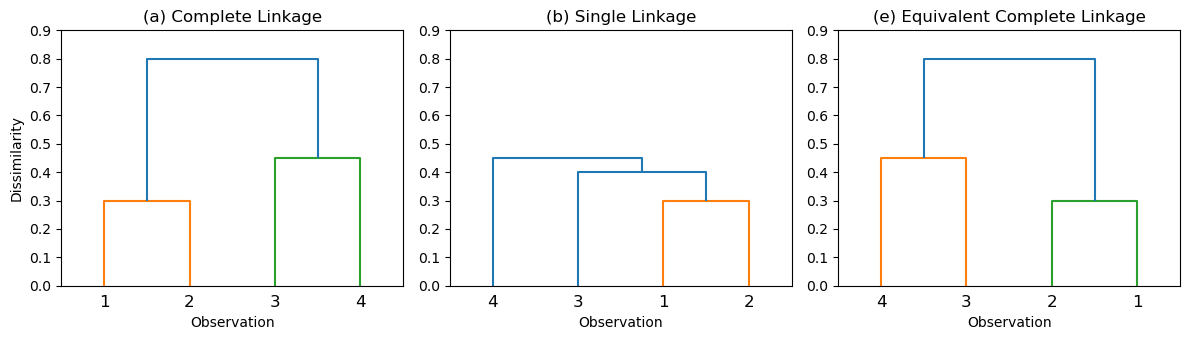

In [25]:
# Question 3(a), (b), (e): Hierarchical clustering dendrograms

distances = np.array([
    [0, 0.30, 0.40, 0.70],
    [0.30, 0, 0.50, 0.80],
    [0.40, 0.50, 0, 0.45],
    [0.70, 0.80, 0.45, 0]
])

condensed = squareform(distances)

Z_complete = linkage(condensed, method="complete")
Z_single = linkage(condensed, method="single")

fig, axes = plt.subplots(1, 3, figsize=(12, 3.5))

dendrogram(
    Z_complete,
    labels=["1", "2", "3", "4"],
    ax=axes[0]
)
axes[0].set_title("(a) Complete Linkage")
axes[0].set_ylabel("Dissimilarity")

dendrogram(
    Z_single,
    labels=["1", "2", "3", "4"],
    ax=axes[1]
)
axes[1].set_title("(b) Single Linkage")

dendrogram(
    Z_complete,
    labels=["1", "2", "3", "4"],
    ax=axes[2],
    count_sort="descending"
)
axes[2].set_title("(e) Equivalent Complete Linkage")

for ax in axes:
    ax.set_xlabel("Observation")
    ax.set_ylim(0, 0.9)

plt.tight_layout()
plt.show()